# 03 — Treinamento Neural Multi-Task, Tuning Optuna, Avaliação (20%) e Inferência Exportada

Cobre as **Etapas 5, 6 e 7** (`docs/5_modelagem_e_treino.md`, `docs/6_avaliacao.md`, `docs/7_exportacao_e_inferencia.md`).

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import EVALUATION_SUMMARY_PATH, FIGURES_DIR, MODELS_DIR, QUALITATIVE_CASES_PATH, RECOMMENDER_ARTIFACT_DIR
from src.serving.inference import RecommenderService

df_trials = pd.read_csv(MODELS_DIR / 'optuna_trials.csv')
print('Top 10 trials da busca Optuna (val_ndcg@3):')
display(df_trials.head(10))

Top 10 trials da busca Optuna (val_ndcg@3):


,trial,val_ndcg@3,best_epoch,arch,lr,dropout,weight_decay,batch_size,w_base,w_qty,pos_weight_cap,lambda_hier
0,13,0.4434,14,128_64_32,0.001444,0.377304,0.006602,128,0.571264,0.581010,3.324089,0.109848
1,23,0.4420,17,128_64_32,0.000843,0.384500,0.002210,128,0.445021,0.535843,3.547982,0.115277
2,21,0.4338,2,128_64,0.002981,0.356181,0.000505,32,0.304050,0.654802,1.756970,0.313916
3,24,0.4337,25,128_64_32,0.000980,0.386728,0.004997,128,0.420882,0.530543,2.442261,0.057718
4,28,0.4323,13,128_64_32,0.001610,0.348868,0.004676,128,0.551953,0.604301,2.966884,0.033235
5,5,0.4308,45,128_64_32,0.000370,0.446066,0.002074,128,0.936172,0.637404,3.699446,0.033320
6,7,0.4307,7,128_64,0.002625,0.298139,0.000370,32,0.328286,0.581846,2.100246,0.228857
7,19,0.4294,50,128_64_32,0.000438,0.435836,0.002914,128,1.014408,0.636506,3.041330,0.041756
8,26,0.4293,27,128_64_32,0.000623,0.387595,0.000913,128,0.561515,0.482199,3.519807,0.009280
9,8,0.4269,10,64_32,0.002514,0.218639,0.000017,128,1.027308,0.580042,4.050112,0.361652


## Curvas de Treinamento e Comparação Final no Teste Hold-Out (20%)

,modelo,sku_mrr,sku_hit_rate@1,sku_recall@1,sku_precision@1,sku_ndcg@1,sku_hit_rate@3,sku_recall@3,sku_precision@3,sku_ndcg@3,sku_coverage@3,sku_hit_rate@5,sku_recall@5,sku_precision@5,sku_ndcg@5,base_hit_rate@3,base_ndcg@3,qty_mae,qty_exact_acc
0,Baseline 1: Popularidade,0.3451,0.1601,0.1601,0.1601,0.1601,0.3879,0.3879,0.1293,0.2889,0.1765,0.5694,0.5694,0.1139,0.3640,0.4875,0.3437,0.4128,0.7651
1,Baseline 2: Co-ocorrência,0.3964,0.2100,0.2100,0.2100,0.2100,0.4591,0.4591,0.1530,0.3527,0.2941,0.6477,0.6477,0.1295,0.4303,0.5943,0.4419,0.4164,0.7616
2,BasketDAE (Autoencoder),0.3587,0.1922,0.1922,0.1922,0.1922,0.3879,0.3879,0.1293,0.3035,0.6176,0.5516,0.5516,0.1103,0.3712,0.5409,0.4076,0.4128,0.7651
3,MLP Multi-Task (Principal),0.4032,0.2384,0.2384,0.2384,0.2384,0.4413,0.4413,0.1471,0.3552,0.2941,0.5979,0.5979,0.1196,0.4199,0.5872,0.4650,0.4199,0.7544


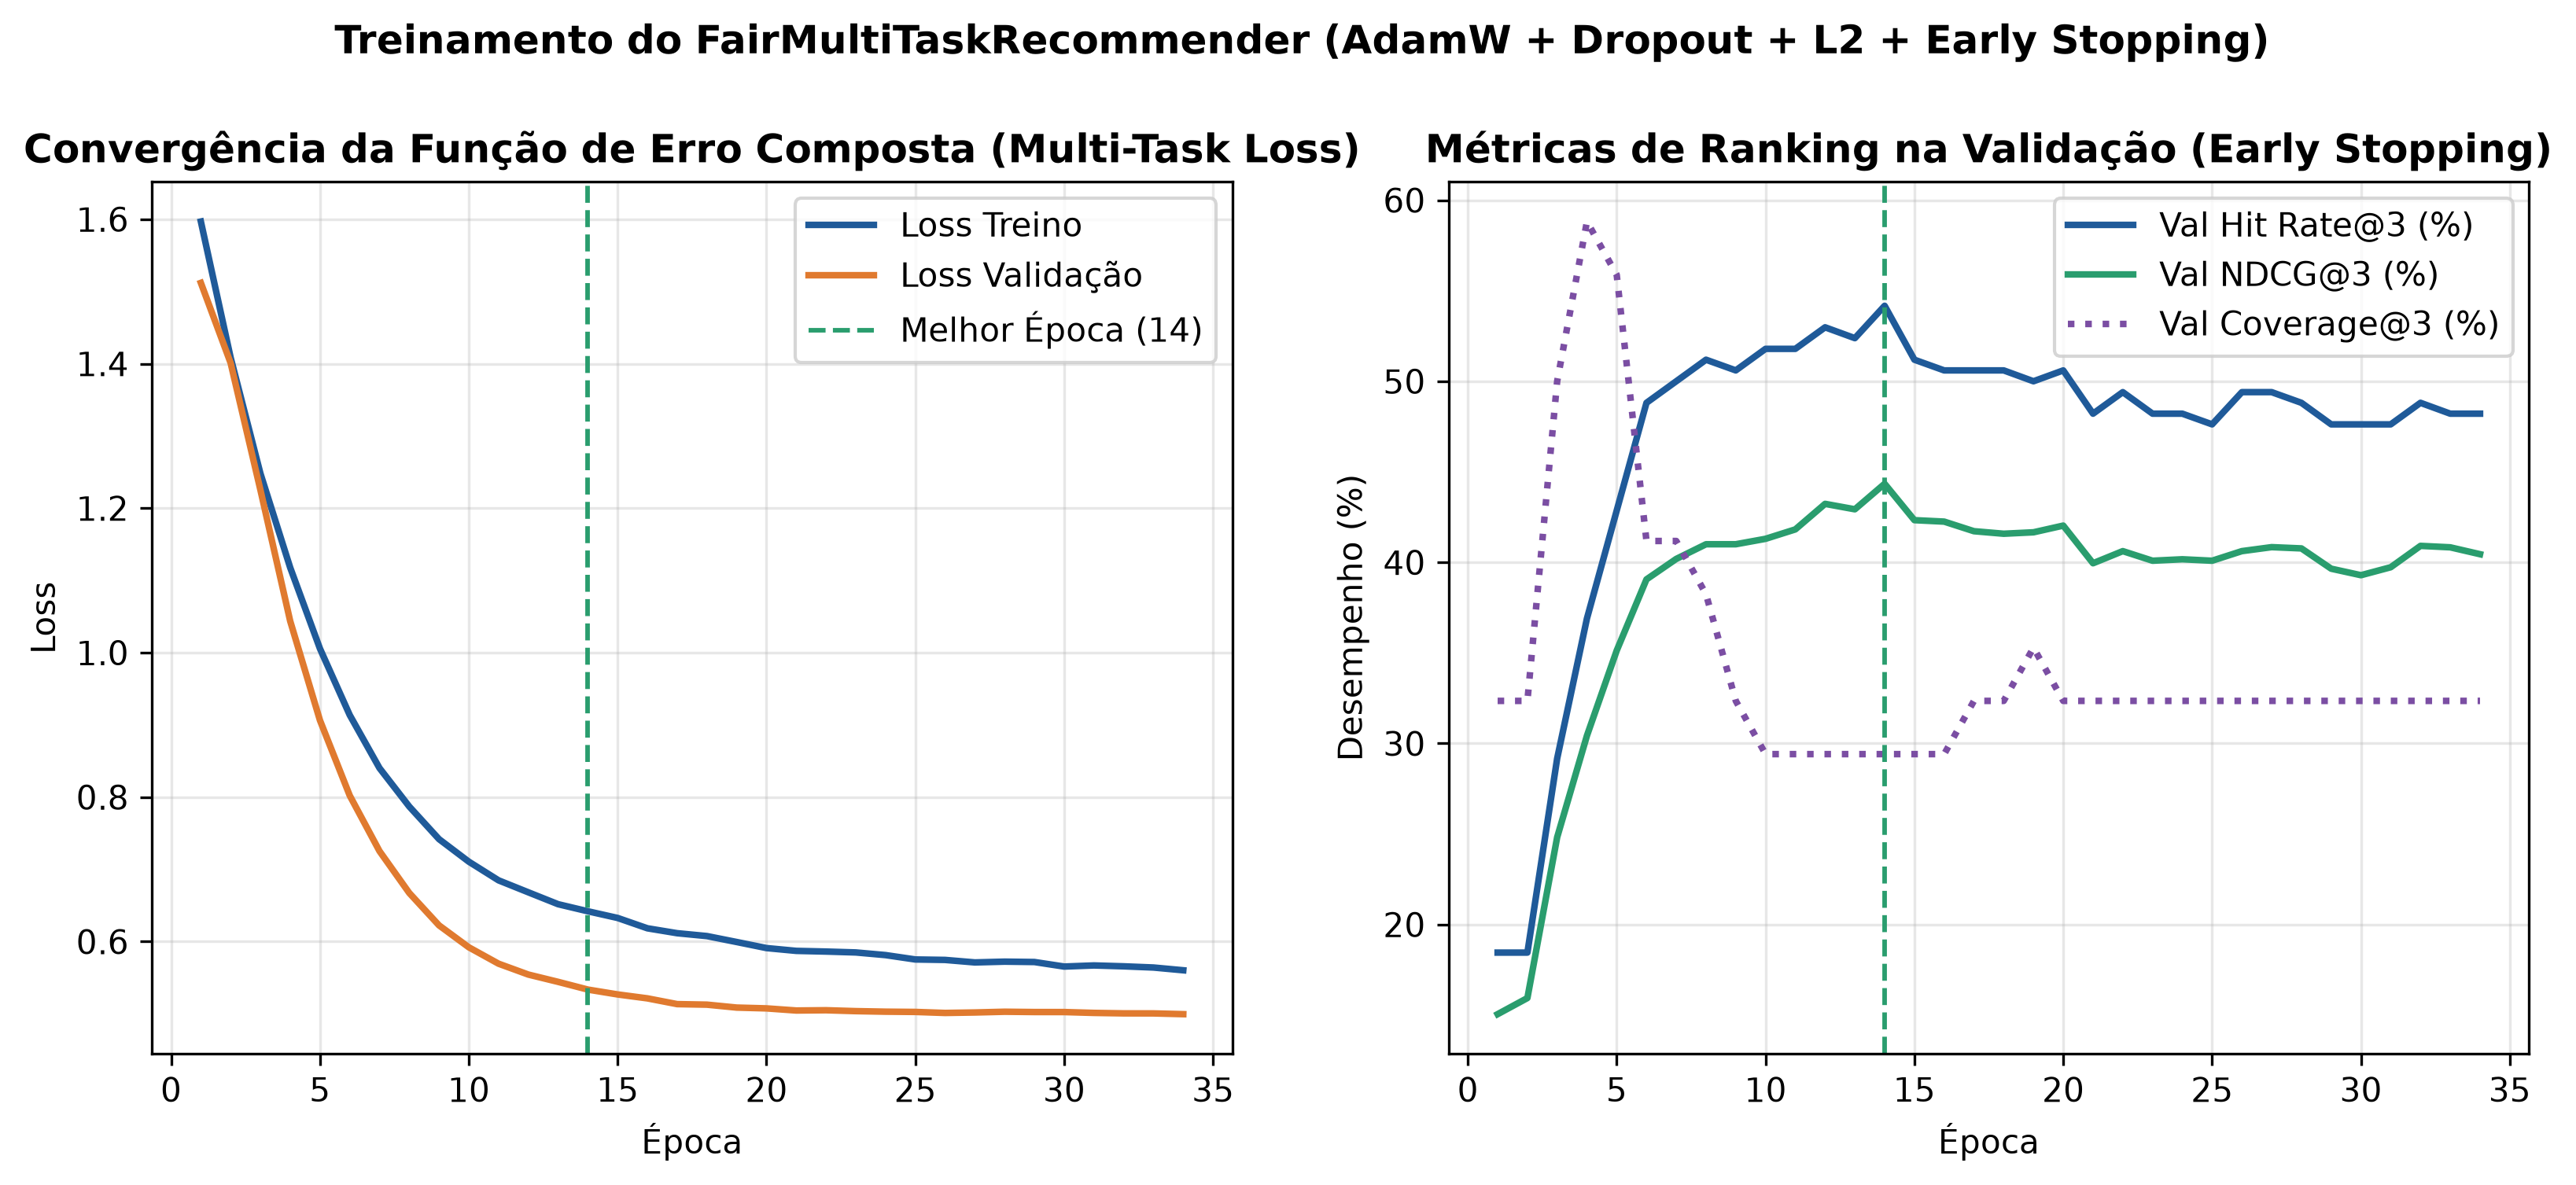

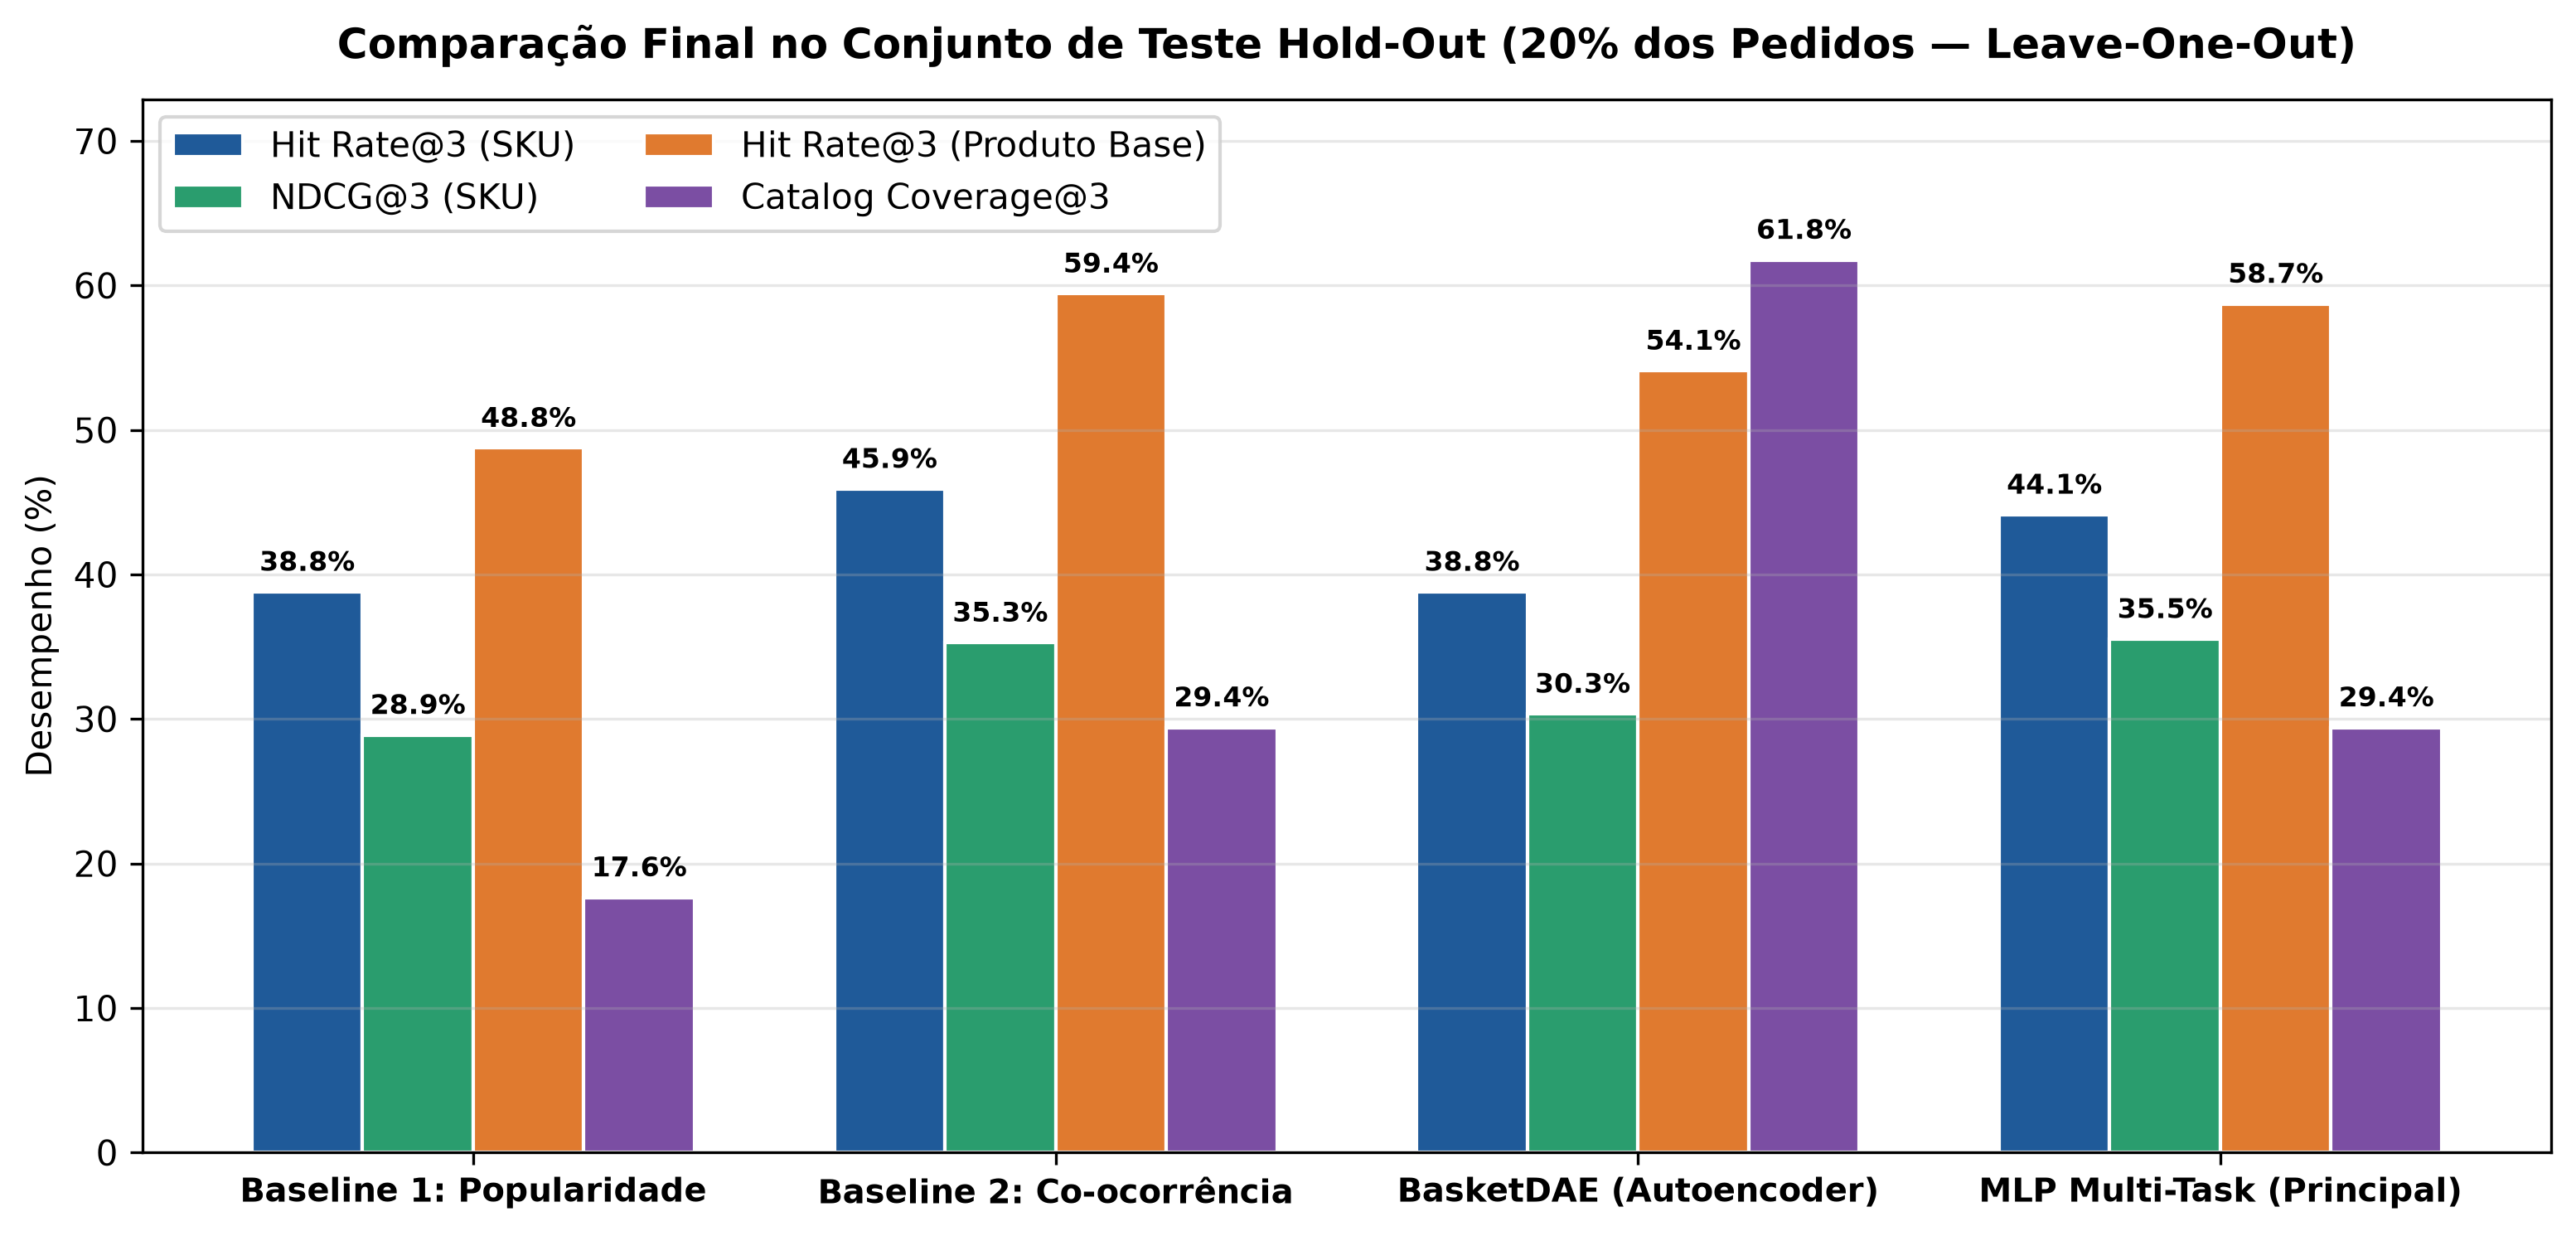

In [2]:
df_eval = pd.read_csv(EVALUATION_SUMMARY_PATH)
display(df_eval)
display(Image(filename=str(FIGURES_DIR / '07_curvas_treinamento.png'), width=850))
display(Image(filename=str(FIGURES_DIR / '08_comparacao_modelos.png'), width=850))

## Demonstração do Modelo Exportado (`RecommenderService`) e Filtro de Estoque Top-3

In [3]:
service = RecommenderService.from_artifact(RECOMMENDER_ARTIFACT_DIR)
cart = [{'sku_norm': 'Alfajor Preto (x1)', 'qtd_pacotes': 2}]
recs = service.recommend(cart, hora=15, dia_semana=5, top_k=3)
print('Top-3 Recomendações com todo estoque disponível:')
display(pd.DataFrame(recs))

# Simular falta de estoque do Top-1 -> ranking pula automaticamente para o próximo!
sem_estoque = recs[0]['sku_norm']
disponiveis = [s['sku_norm'] for s in service.catalogo['skus'] if s['sku_norm'] != sem_estoque]
recs_filtrado = service.recommend(cart, hora=15, dia_semana=5, top_k=3, available_skus=disponiveis)
print(f'Top-3 após remover "{sem_estoque}" do estoque (pula automaticamente):')
display(pd.DataFrame(recs_filtrado))

Top-3 Recomendações com todo estoque disponível:


,rank,sku_id,sku_norm,produto_base,produto_com_multiplicador,tipo_embalagem,multiplicador,qtd_pacotes,qtd_unidades_base,preco_unitario,preco_pacote,valor_estimado,confianca
0,1,0,Alfajor Branco (x1),Alfajor Branco,Alfajor Branco (Unidade),Unidade,1,1,1,6.00,6.0,6.0,0.5108
1,2,27,Rapadura Assada (x1),Rapadura Assada,Rapadura Assada (Unidade),Unidade,1,2,2,5.00,5.0,10.0,0.4629
2,3,29,Rapadura Assada (x6),Rapadura Assada,Rapadura Assada (Pacote x6),Pacote,6,1,6,4.17,25.0,25.0,0.3721


Top-3 após remover "Alfajor Branco (x1)" do estoque (pula automaticamente):


,rank,sku_id,sku_norm,produto_base,produto_com_multiplicador,tipo_embalagem,multiplicador,qtd_pacotes,qtd_unidades_base,preco_unitario,preco_pacote,valor_estimado,confianca
0,1,27,Rapadura Assada (x1),Rapadura Assada,Rapadura Assada (Unidade),Unidade,1,2,2,5.00,5.0,10.0,0.4629
1,2,29,Rapadura Assada (x6),Rapadura Assada,Rapadura Assada (Pacote x6),Pacote,6,1,6,4.17,25.0,25.0,0.3721
2,3,15,Cri-Cri 200g (x1),Cri-Cri 200g,Cri-Cri 200g (Unidade),Unidade,1,1,1,8.00,8.0,8.0,0.3654


## Casos Qualitativos Reais do Teste Hold-Out (20%)

In [4]:
display(Markdown(QUALITATIVE_CASES_PATH.read_text(encoding='utf-8')))

# Análise Qualitativa — Exemplos Reais no Conjunto de Teste (20%)

Amostra de cestas reais do conjunto de teste Hold-Out avaliadas pelo `FairMultiTaskRecommender` (Modelo Genérico).

## Caso 1 — Pedido `27defda6...` (Sáb, 13h) — ACERTO NO TOP-3
- **Carrinho de Entrada:** **Cuca Enrolada de Amendoim (Unidade)** (2 pct)
- **Item Real Comprado (Ground Truth):** `Cuca Alemã (Unidade)` (mult `x1`, `1` pct = `1` un.)

| Rank | Produto Recomendado (SKU) | Produto Base | Mult | Qtd Pct | Qtd Un | Preço Pct | Confiança |
| :-: | :--- | :--- | :-: | :-: | :-: | :-: | :-: |
| 1 | Cuca Alemã (Unidade) **[REAL]** | Cuca Alemã | x1 | 1 | 1 | R$ 25.00 | 67.8% |
| 2 | Rapadura de Melado (Unidade) | Rapadura de Melado | x1 | 1 | 1 | R$ 7.00 | 31.7% |
| 3 | Rapadura Assada (Unidade) | Rapadura Assada | x1 | 1 | 1 | R$ 5.00 | 28.0% |

## Caso 2 — Pedido `29ef7221...` (Sáb, 20h) — ACERTO NO TOP-3
- **Carrinho de Entrada:** **Cuca Enrolada de Amendoim (Unidade)** (2 pct)
- **Item Real Comprado (Ground Truth):** `Cuca Alemã (Unidade)` (mult `x1`, `2` pct = `2` un.)

| Rank | Produto Recomendado (SKU) | Produto Base | Mult | Qtd Pct | Qtd Un | Preço Pct | Confiança |
| :-: | :--- | :--- | :-: | :-: | :-: | :-: | :-: |
| 1 | Cuca Alemã (Unidade) **[REAL]** | Cuca Alemã | x1 | 1 | 1 | R$ 25.00 | 62.0% |
| 2 | Rapadura de Melado (Unidade) | Rapadura de Melado | x1 | 1 | 1 | R$ 7.00 | 32.1% |
| 3 | Rapadura Assada (Unidade) | Rapadura Assada | x1 | 1 | 1 | R$ 5.00 | 29.6% |

## Caso 3 — Pedido `31784711...` (Sex, 19h) — ACERTO NO TOP-3
- **Carrinho de Entrada:** **Rapadura Assada (Pacote x6)** (1 pct)
- **Item Real Comprado (Ground Truth):** `Alfajor Preto (Unidade)` (mult `x1`, `1` pct = `1` un.)

| Rank | Produto Recomendado (SKU) | Produto Base | Mult | Qtd Pct | Qtd Un | Preço Pct | Confiança |
| :-: | :--- | :--- | :-: | :-: | :-: | :-: | :-: |
| 1 | Alfajor Preto (Unidade) **[REAL]** | Alfajor Preto | x1 | 1 | 1 | R$ 6.00 | 44.2% |
| 2 | Cuca Enrolada de Amendoim (Unidade) | Cuca Enrolada de Amendoim | x1 | 1 | 1 | R$ 15.00 | 40.6% |
| 3 | Rapadura de Melado (Pacote x3) | Rapadura de Melado | x3 | 1 | 3 | R$ 20.00 | 38.7% |

## Caso 4 — Pedido `39f3a47e...` (Sex, 19h) — ACERTO NO TOP-3
- **Carrinho de Entrada:** **Cuca Enrolada de Amendoim (Unidade)** (1 pct)
- **Item Real Comprado (Ground Truth):** `Cuca Alemã (Unidade)` (mult `x1`, `1` pct = `1` un.)

| Rank | Produto Recomendado (SKU) | Produto Base | Mult | Qtd Pct | Qtd Un | Preço Pct | Confiança |
| :-: | :--- | :--- | :-: | :-: | :-: | :-: | :-: |
| 1 | Cuca Alemã (Unidade) **[REAL]** | Cuca Alemã | x1 | 1 | 1 | R$ 25.00 | 50.9% |
| 2 | Rapadura de Melado (Unidade) | Rapadura de Melado | x1 | 1 | 1 | R$ 7.00 | 35.4% |
| 3 | Rapadura Assada (Pacote x6) | Rapadura Assada | x6 | 1 | 6 | R$ 25.00 | 29.2% |

## Caso 5 — Pedido `0bc6773e...` (Qua, 13h) — ACERTO NO TOP-3
- **Carrinho de Entrada:** **Rapadura Assada (Unidade)** (1 pct)
- **Item Real Comprado (Ground Truth):** `Cuca Enrolada de Amendoim (Unidade)` (mult `x1`, `1` pct = `1` un.)

| Rank | Produto Recomendado (SKU) | Produto Base | Mult | Qtd Pct | Qtd Un | Preço Pct | Confiança |
| :-: | :--- | :--- | :-: | :-: | :-: | :-: | :-: |
| 1 | Rapadura de Melado (Unidade) | Rapadura de Melado | x1 | 1 | 1 | R$ 7.00 | 40.0% |
| 2 | Cuca Enrolada de Amendoim (Unidade) **[REAL]** | Cuca Enrolada de Amendoim | x1 | 1 | 1 | R$ 15.00 | 34.1% |
| 3 | Alfajor Preto (Unidade) | Alfajor Preto | x1 | 1 | 1 | R$ 6.00 | 27.2% |

## Caso 6 — Pedido `2340a331...` (Qui, 12h) — ACERTO NO TOP-3
- **Carrinho de Entrada:** **Alfajor Preto (Unidade)** (2 pct)
- **Item Real Comprado (Ground Truth):** `Alfajor Branco (Unidade)` (mult `x1`, `2` pct = `2` un.)

| Rank | Produto Recomendado (SKU) | Produto Base | Mult | Qtd Pct | Qtd Un | Preço Pct | Confiança |
| :-: | :--- | :--- | :-: | :-: | :-: | :-: | :-: |
| 1 | Rapadura Assada (Unidade) | Rapadura Assada | x1 | 1 | 1 | R$ 5.00 | 43.3% |
| 2 | Alfajor Branco (Unidade) **[REAL]** | Alfajor Branco | x1 | 1 | 1 | R$ 6.00 | 39.8% |
| 3 | Rapadura de Melado (Unidade) | Rapadura de Melado | x1 | 1 | 1 | R$ 7.00 | 39.1% |

## Caso 7 — Pedido `063384d8...` (Sex, 19h) — FORA DO TOP-3
- **Carrinho de Entrada:** **Cri-Cri 200g (Unidade)** (1 pct)
- **Item Real Comprado (Ground Truth):** `Alfajor Preto (Unidade)` (mult `x1`, `1` pct = `1` un.)

| Rank | Produto Recomendado (SKU) | Produto Base | Mult | Qtd Pct | Qtd Un | Preço Pct | Confiança |
| :-: | :--- | :--- | :-: | :-: | :-: | :-: | :-: |
| 1 | Amendoim Temperado (Unidade) | Amendoim Temperado | x1 | 1 | 1 | R$ 8.00 | 42.4% |
| 2 | Rapadura de Melado (Unidade) | Rapadura de Melado | x1 | 1 | 1 | R$ 7.00 | 39.1% |
| 3 | Cuca Enrolada de Amendoim (Unidade) | Cuca Enrolada de Amendoim | x1 | 1 | 1 | R$ 15.00 | 37.6% |

## Caso 8 — Pedido `0c6f54dc...` (Sex, 20h) — FORA DO TOP-3
- **Carrinho de Entrada:** **Rapadura Assada (Pacote x6)** (1 pct)
- **Item Real Comprado (Ground Truth):** `Cri-Cri 200g (Unidade)` (mult `x1`, `1` pct = `1` un.)

| Rank | Produto Recomendado (SKU) | Produto Base | Mult | Qtd Pct | Qtd Un | Preço Pct | Confiança |
| :-: | :--- | :--- | :-: | :-: | :-: | :-: | :-: |
| 1 | Alfajor Preto (Unidade) | Alfajor Preto | x1 | 1 | 1 | R$ 6.00 | 45.1% |
| 2 | Cuca Enrolada de Amendoim (Unidade) | Cuca Enrolada de Amendoim | x1 | 1 | 1 | R$ 15.00 | 41.4% |
| 3 | Rapadura de Melado (Pacote x3) | Rapadura de Melado | x3 | 1 | 3 | R$ 20.00 | 39.6% |
